# Which song fits this playlist?
### Choosing between two candidates using five example songs

**Research question:** Given five songs from a playlist, can we identify which of two
candidate songs also belongs to that playlist?

We compare familiar rules—popularity, artist overlap, and audio similarity—with
logistic regression. One candidate is a hidden playlist member; the other is sampled
uniformly from songs outside the playlist. Random guessing scores **50%**.

Sections 1–5 cover the task, data, models, evaluation, and findings with related work.
The notebook contains the complete implementation and executed results. To rerun,
keep `data/songs620.csv` here, put the CSV beside this notebook, or set `SONGS620_PATH`.
Install `requirements.txt`, then run all cells from the notebook's folder.

## 1 · Predictive task

For each eligible playlist, sample six **distinct** songs without replacement.
Five form the visible context, and the sixth is the hidden member. Sample a second
candidate uniformly from all distinct catalogue tracks absent from the **entire**
playlist, and randomly place the hidden member in candidate A or B. Predict which
candidate is the member. Order and original track positions play no role.

**Example:** five songs from a playlist → candidate A versus candidate B → choose A or B.
The label is observed playlist membership, not a judgment that the other song sounds bad.

**Evaluation plan:** fix seed 42 and split whole playlists 80%/10%/10% into training,
validation, and test before making examples. Draw ten examples per eligible playlist
in each split. Examples can reuse songs within a playlist, so uncertainty is measured
by resampling **playlists**, not by treating every query as independent.

Choose regularization and the primary learned model on validation accuracy, freeze
these choices, then evaluate test accuracy. Ties get half credit: the expected result
of a fair coin flip. All eligible playlists supply ten queries, giving them equal weight.

**What success means:** accuracy above the 50% random baseline, with a playlist-bootstrap
interval and paired comparisons against audio similarity. A higher score alone does
not establish that learning improves on a simple rule.

**Scope:** this is a known-catalogue, new-playlist task. Static metadata may be looked up
for every candidate. Playlist-derived popularity and fitted preprocessing use training
playlists only. Track overlap between splits is allowed; playlist overlap is not.

In [1]:
from __future__ import annotations

import hashlib
import json
import os
import platform
from pathlib import Path

ROOT = Path.cwd()
OUT = ROOT / 'output' / 'playlist_matching'
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / 'tmp' / 'matplotlib'))
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

SEED = 42
CONTEXT_SIZE = 5
QUERIES_PER_PLAYLIST = 10
C_GRID = [0.01, 0.1, 1.0, 10.0]
AUDIO = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
         'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms']
FEATURES = ['closeness_' + x for x in AUDIO] + ['nearest_audio', 'artist_fraction']
MODEL_COLUMNS = {'Logistic: audio': list(range(11)),
                 'Logistic: audio + artist': list(range(12))}



from IPython.display import display, Image, Markdown
_thread_limit = threadpool_limits(limits=4)

## 2 · Data and preparation

The local `songs620.csv` contains playlist IDs, track and artist URIs, positions,
and numeric audio descriptors. Playlist membership supplies labels; danceability,
energy, loudness, speechiness, acousticness, instrumentalness, liveness, valence,
tempo, and duration supply audio predictors. We do not fetch Spotify URLs.

Spotify's [Million Playlist Dataset introduction](https://engineering.atspotify.com/2018/05/introducing-the-million-playlist-dataset-and-recsys-challenge-2018)
describes a public-playlist research resource. The local CSV has a compatible schema,
but its exact sampling and audio-enrichment history are **unverified**. We therefore
describe the supplied file directly rather than assume its provenance. It has no
listener IDs, satisfaction labels, or timestamps for a chronological split.

Deduplicate `(playlist, track)` memberships so a repeated recording does not count as
two distinct songs. Identify recordings by URI, not name. Reject missing or conflicting
modeled metadata and nonfinite audio values. Playlists with fewer than six distinct
tracks stay in their original split but cannot supply examples.

Log-transform tempo and duration using `log1p`, then standardize the ten audio features
using **distinct tracks in training playlists only**. These transformations are fitted
once and applied unchanged to validation and test candidates. Popularity counts the
number of training playlists containing each track.

In [2]:
def find_dataset():
    override = os.environ.get('SONGS620_PATH')
    if override:
        path = Path(override).expanduser()
        if not path.is_file():
            raise FileNotFoundError(f'SONGS620_PATH does not exist: {path}')
        return path
    for path in [ROOT / 'songs620.csv', ROOT / 'data' / 'songs620.csv']:
        if path.is_file():
            return path
    raise FileNotFoundError('Put songs620.csv in data/ or set SONGS620_PATH.')


def prepare_data():
    OUT.mkdir(parents=True, exist_ok=True)
    path = find_dataset()
    raw = pd.read_csv(path)
    required = ['pid', 'track_uri', 'artist_uri'] + AUDIO
    if raw[required].isna().any().any():
        raise ValueError('Missing modeled metadata requires an explicit handling rule.')
    if not np.isfinite(raw[AUDIO].to_numpy()).all():
        raise ValueError('Nonfinite audio values.')
    metadata = raw.groupby('track_uri')[['artist_uri'] + AUDIO].nunique()
    if metadata.gt(1).any().any():
        raise ValueError('Conflicting metadata for a recording.')
    tracks = raw.drop_duplicates('track_uri').sort_values('track_uri').reset_index(drop=True)
    lookup = dict(zip(tracks.track_uri, tracks.index))
    raw['item'] = raw.track_uri.map(lookup)
    members = {int(pid): np.sort(g.item.unique()) for pid, g in raw.groupby('pid')}
    pids = np.random.default_rng(SEED).permutation(sorted(members))
    n_train, n_val = int(.8 * len(pids)), int(.1 * len(pids))
    split = {'train': pids[:n_train], 'validation': pids[n_train:n_train+n_val],
             'test': pids[n_train+n_val:]}
    train_items = np.unique(np.concatenate([members[int(p)] for p in split['train']]))
    # Each distinct training track contributes once to the audio scaler.
    audio = tracks[AUDIO].to_numpy(dtype=float)
    for col in ['tempo', 'duration_ms']:
        j = AUDIO.index(col)
        if (audio[:, j] < 0).any():
            raise ValueError(f'Negative {col}.')
        audio[:, j] = np.log1p(audio[:, j])
    scaler = StandardScaler().fit(audio[train_items])
    z = scaler.transform(audio)
    pop = np.zeros(len(tracks), dtype=int)
    for pid in split['train']:
        pop[members[int(pid)]] += 1
    split_frame = pd.DataFrame([(int(p), s) for s, ids in split.items() for p in ids],
                               columns=['pid', 'split'])
    split_frame.to_csv(OUT / 'playlist_split.csv', index=False)
    tracks.assign(item=tracks.index).to_csv(OUT / 'catalogue.csv', index=False)
    summary = {'rows': len(raw), 'unique_memberships': sum(map(len, members.values())),
               'tracks': len(tracks), 'playlists': len(members),
               'artists': int(tracks.artist_uri.nunique()),
               'repeated_memberships_removed': int(raw.duplicated(['pid', 'item']).sum()),
               'singleton_tracks': int(raw.groupby('item').pid.nunique().eq(1).sum()),
               'eligible_playlists': {s: sum(len(members[int(p)]) >= 6 for p in ids)
                                      for s, ids in split.items()},
               'split_playlists': {s: len(ids) for s, ids in split.items()},
               'dataset_sha256': hashlib.sha256(path.read_bytes()).hexdigest()}
    return dict(raw=raw, tracks=tracks, members=members, split=split, z=z,
                artists=tracks.artist_uri.to_numpy(), pop=pop, train_items=train_items,
                audio_scaler=scaler, summary=summary)


def make_queries(members, pids, catalogue_size, seed, per_playlist=QUERIES_PER_PLAYLIST):
    rng = np.random.default_rng(seed)
    rows = []
    for pid in sorted(pids):
        playlist = members[int(pid)]
        if len(playlist) < CONTEXT_SIZE + 1:
            continue
        outsiders = np.setdiff1d(np.arange(catalogue_size), playlist, assume_unique=True)
        if not len(outsiders):
            raise ValueError('No nonmember candidates.')
        for q in range(per_playlist):
            six = rng.choice(playlist, CONTEXT_SIZE + 1, replace=False)
            positive, negative = int(six[-1]), int(rng.choice(outsiders))
            label = int(rng.integers(2))  # 1 means candidate A is the member.
            a, b = (positive, negative) if label else (negative, positive)
            rows.append([int(pid), q, *map(int, six[:5]), a, b, label])
    return pd.DataFrame(rows, columns=['pid', 'query', 'h0', 'h1', 'h2', 'h3', 'h4',
                                       'candidate_a', 'candidate_b', 'label'])

In [3]:
data = prepare_data()
display(pd.Series(data['summary']).drop(['eligible_playlists', 'split_playlists', 'dataset_sha256']).to_frame('value'))
display(pd.DataFrame({'all_playlists': data['summary']['split_playlists'],
                      'eligible_playlists': data['summary']['eligible_playlists']}))
display(data['tracks'][['track_name', 'artist_name'] + AUDIO].head())

,value
rows,66263
unique_memberships,65409
tracks,36203
playlists,1000
artists,9963
repeated_memberships_removed,854
singleton_tracks,26901


,all_playlists,eligible_playlists
train,800,795
validation,100,98
test,100,100


,track_name,artist_name,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,Still Got Time,ZAYN,0.748,0.627,-6.029,0.0644,0.131000,0.000000,0.0852,0.524,120.963,188491
1,Yee - Original Mix,Deorro,0.732,0.989,-4.172,0.0483,0.102000,0.748000,0.0551,0.684,127.984,210000
2,Live and Let Live,Red Allen & The Kentuckians,0.445,0.514,-12.202,0.0314,0.495000,0.000177,0.3450,0.818,115.357,167653
3,I've Failed You,Kittie,0.511,0.958,-3.688,0.0381,0.000021,0.000324,0.0893,0.678,102.015,131853
4,Heart and Soul,Kevin Jonas,0.605,0.846,-4.581,0.0778,0.000738,0.000001,0.0530,0.764,132.997,177773


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist([len(v) for v in data['members'].values()], bins=30, color='#4786b8')
axes[0].set(xlabel='Distinct songs per playlist', ylabel='Playlists', title='Playlist sizes')
counts = data['raw'].groupby('item').pid.nunique()
axes[1].hist(counts, bins=30, color='#238b45')
axes[1].set(xlabel='Playlists containing a track', ylabel='Distinct tracks', title='Track support')
axes[1].set_yscale('log')
fig.tight_layout()
display(fig)
plt.close(fig)
print(f"{data['summary']['singleton_tracks'] / len(data['tracks']):.1%} of tracks occur in just one playlist.")

<Figure size 1000x350 with 2 Axes>

74.3% of tracks occur in just one playlist.


Many songs appear in only one playlist, limiting identity-based retrieval. Static audio
features still describe these songs. Playlist matching between two candidates reduces
the search burden while retaining an observed behavioral label.

The [earlier Spotify project presentation](https://docs.google.com/presentation/d/1er6tXVBatdB-UJQ5t9p4c7T3HA4U4P42Cuk8XslenCA/edit)
in Google Drive motivates grouping and recommending songs using their features. It is
background context, not an additional source of training labels or measured accuracy.

## 3 · Models and fitting

Each model gives candidate A and B a compatibility score and chooses the higher one.

| Model | Compatibility rule |
|---|---|
| Random | Fair coin; expected accuracy 50% |
| Popularity | Number of training playlists containing the candidate |
| Artist overlap | Fraction of the five context songs sharing the candidate's artist |
| Audio distance | Negative sum of absolute standardized differences from the context's mean audio vector |
| Logistic: audio | Learn weights for ten per-feature closeness values and distance to the nearest context song |
| Logistic: audio + artist | Add the artist-overlap feature to the same learned model |

For each audio dimension, closeness is the negative absolute difference between the
candidate and the five-song mean. Nearest-song closeness is negative Euclidean distance
to the closest of the five songs. Higher values mean greater similarity.

**Simple explanation of logistic regression:** learn how much weight to give similarities
such as energy, tempo, and artist overlap when choosing between the two songs.

Subtract B's features from A's features, then fit logistic regression to predict whether
A is the member. Include each training pair and its swapped version with the opposite
label; omit the intercept. Reversing A and B therefore reverses the score. Scale feature
differences using training examples only. There are no track-ID, album-ID, playlist-ID,
or co-occurrence predictors, so a training playlist cannot leak its membership through
its own historical counts into a learned feature.

Test C ∈ {0.01, 0.1, 1, 10} for each learned model. Choose the highest validation
accuracy, breaking ties toward smaller C. Choose the primary learned model by validation
accuracy, breaking ties toward fewer features. Keep the original training fit after
selection. Coefficients describe associations under this sampling scheme, not causes.

In [5]:
def candidate_features(data, contexts, candidates):
    seeds = data['z'][contexts]
    candidate = data['z'][candidates]
    centroid = seeds.mean(axis=1)
    closeness = -np.abs(candidate - centroid)
    nearest = -np.sqrt(((seeds - candidate[:, None, :]) ** 2).sum(axis=2)).min(axis=1)
    artist_fraction = (data['artists'][contexts] == data['artists'][candidates, None]).mean(axis=1)
    return np.column_stack([closeness, nearest, artist_fraction])


def query_features(data, queries):
    contexts = queries[[f'h{i}' for i in range(5)]].to_numpy(dtype=int)
    a = candidate_features(data, contexts, queries.candidate_a.to_numpy())
    b = candidate_features(data, contexts, queries.candidate_b.to_numpy())
    return a - b


def baseline_scores(data, queries, delta):
    # Greater is always stronger evidence for candidate A.
    return {'Random (expected)': np.zeros(len(queries)),
            'Popularity': data['pop'][queries.candidate_a] - data['pop'][queries.candidate_b],
            'Artist overlap': delta[:, -1],
            'Audio distance': delta[:, :10].sum(axis=1)}


def correct_credit(scores, labels):
    """Fair random tie-breaking has expected correctness 0.5."""
    scores, labels = np.asarray(scores), np.asarray(labels)
    return np.where(scores == 0, .5, (scores > 0) == labels).astype(float)


def fit_models(train_x, train_y, val_x, val_y):
    fitted, grid, selected = {}, [], {}
    for name, columns in MODEL_COLUMNS.items():
        # Mirrored pairs prevent candidate-position bias and enforce swap symmetry.
        x = np.vstack([train_x[:, columns], -train_x[:, columns]])
        y = np.concatenate([train_y, 1 - train_y])
        options = []
        for c in C_GRID:
            model = make_pipeline(StandardScaler(with_mean=False),
                                  LogisticRegression(C=c, fit_intercept=False, max_iter=2000))
            model.fit(x, y)
            accuracy = correct_credit(model.decision_function(val_x[:, columns]), val_y).mean()
            grid.append({'model': name, 'C': c, 'validation_accuracy': accuracy})
            options.append((accuracy, -c, model))
        accuracy, neg_c, model = max(options, key=lambda v: (v[0], v[1]))
        fitted[name] = model
        selected[name] = {'C': -neg_c, 'validation_accuracy': accuracy}
    primary = max(selected, key=lambda name: (selected[name]['validation_accuracy'],
                                             -len(MODEL_COLUMNS[name])))
    return fitted, pd.DataFrame(grid), selected, primary

## 4 · Evaluation on held-out playlists

Run the fixed experiment below. Accuracy is the fraction of correctly chosen members,
with half credit for exact score ties. The uncertainty interval resamples the 100 held-out
playlists with replacement 10,000 times. Ten queries from the same playlist remain together.
Paired intervals compare models on exactly the same queries and playlists.

All candidate pairs, split assignments, validation scores, frozen model choices,
coefficients, test predictions, subgroup results, and dataset checksum are saved under
`output/playlist_matching/`. Validation chooses the primary model; test results do not.

In [6]:
def bootstrap_interval(values, seed=SEED, draws=10000):
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    averages = values[rng.integers(len(values), size=(draws, len(values)))].mean(axis=1)
    return [float(v) for v in np.quantile(averages, [.025, .975])]


def evaluate(data, queries, delta, models):
    scores = baseline_scores(data, queries, delta)
    scores.update({name: model.decision_function(delta[:, MODEL_COLUMNS[name]])
                   for name, model in models.items()})
    details, metrics = [], []
    for name, score in scores.items():
        d = queries.copy()
        d['model'], d['score_a_minus_b'] = name, score
        d['correct_credit'] = correct_credit(score, queries.label)
        d['tie'] = np.asarray(score) == 0
        positive = np.where(queries.label, queries.candidate_a, queries.candidate_b)
        d['member_seen_in_training'] = data['pop'][positive] > 0
        per_playlist = d.groupby('pid').correct_credit.mean()
        low, high = bootstrap_interval(per_playlist)
        metrics.append({'model': name, 'accuracy': per_playlist.mean(),
                        'ci_low': low, 'ci_high': high, 'tie_fraction': d.tie.mean(),
                        'queries': len(d), 'playlists': len(per_playlist)})
        details.append(d)
    return pd.DataFrame(metrics), pd.concat(details, ignore_index=True)


def paired_comparison(details, first, second):
    table = details.groupby(['pid', 'model']).correct_credit.mean().unstack('model')
    delta = table[first] - table[second]
    low, high = bootstrap_interval(delta)
    return {'first': first, 'second': second, 'difference': float(delta.mean()),
            'ci_low': low, 'ci_high': high, 'playlists': len(delta), 'bootstrap_draws': 10000}


def run_experiment(data=None):
    if data is None:
        data = prepare_data()
    queries = {s: make_queries(data['members'], ids, len(data['tracks']), SEED + i + 1)
               for i, (s, ids) in enumerate(data['split'].items())}
    for name, q in queries.items():
        q.to_csv(OUT / f'{name}_queries.csv', index=False)
    delta = {s: query_features(data, q) for s, q in queries.items()}
    models, grid, selection, primary = fit_models(delta['train'], queries['train'].label.to_numpy(),
                                                  delta['validation'], queries['validation'].label.to_numpy())
    grid.to_csv(OUT / 'validation_grid.csv', index=False)
    frozen = {'models': selection, 'primary_model': primary, 'seed': SEED,
              'context_size': CONTEXT_SIZE, 'queries_per_playlist': QUERIES_PER_PLAYLIST,
              'negative_sampling': 'uniform distinct track outside the complete target playlist'}
    (OUT / 'frozen_selection.json').write_text(json.dumps(frozen, indent=2), encoding='utf-8')
    # Test scores are accessed only after validation selection is frozen.
    metrics, details = evaluate(data, queries['test'], delta['test'], models)
    metrics.to_csv(OUT / 'test_metrics.csv', index=False)
    details.to_csv(OUT / 'test_per_query.csv', index=False)
    coefficients = []
    for name, model in models.items():
        for feature, weight in zip(np.array(FEATURES)[MODEL_COLUMNS[name]], model[-1].coef_[0]):
            coefficients.append({'model': name, 'feature': feature, 'coefficient': weight})
    coefficients = pd.DataFrame(coefficients)
    coefficients.to_csv(OUT / 'coefficients.csv', index=False)
    subgroup = details.groupby(['model', 'member_seen_in_training', 'pid']).correct_credit.mean()
    subgroup = subgroup.groupby(level=[0, 1]).agg(['mean', 'count']).reset_index()
    subgroup.columns = ['model', 'member_seen_in_training', 'accuracy', 'playlists_with_queries']
    subgroup.to_csv(OUT / 'support_subgroups.csv', index=False)
    comparisons = [paired_comparison(details, primary, 'Random (expected)'),
                   paired_comparison(details, primary, 'Audio distance'),
                   paired_comparison(details, 'Logistic: audio + artist', 'Logistic: audio')]
    pd.DataFrame(comparisons).to_csv(OUT / 'paired_comparisons.csv', index=False)
    summary = {'data': data['summary'], 'selection': frozen,
               'query_counts': {s: len(q) for s, q in queries.items()},
               'comparisons': comparisons,
               'environment': {'python': platform.python_version(), 'numpy': np.__version__,
                               'pandas': pd.__version__, 'sklearn': sklearn.__version__}}
    (OUT / 'experiment_summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
    fig, ax = plt.subplots(figsize=(9, 4.8))
    ordered = metrics.iloc[::-1]
    ax.barh(ordered.model, ordered.accuracy, color=['#238b45' if n == primary else '#4786b8'
                                                  for n in ordered.model])
    ax.errorbar(ordered.accuracy, np.arange(len(ordered)),
                xerr=np.vstack([ordered.accuracy-ordered.ci_low, ordered.ci_high-ordered.accuracy]),
                fmt='none', ecolor='black', capsize=3)
    ax.axvline(.5, color='black', linestyle='--', label='Random: 50%')
    ax.set(xlim=(0, 1), xlabel='Two-candidate accuracy (95% playlist bootstrap interval)',
           title='Which song fits this playlist?')
    ax.legend(loc='lower right')
    fig.tight_layout()
    fig.savefig(OUT / 'accuracy.png', dpi=160)
    plt.close(fig)
    return dict(data=data, queries=queries, models=models, grid=grid, metrics=metrics,
                details=details, coefficients=coefficients, subgroups=subgroup, summary=summary)

,queries
train,7950
validation,980
test,1000


,model,C,validation_accuracy
0,Logistic: audio,0.01,0.745918
1,Logistic: audio,0.10,0.743878
2,Logistic: audio,1.00,0.744898
3,Logistic: audio,10.00,0.744898
4,Logistic: audio + artist,0.01,0.779592
5,Logistic: audio + artist,0.10,0.778571
6,Logistic: audio + artist,1.00,0.778571
7,Logistic: audio + artist,10.00,0.778571


Validation-selected primary model: Logistic: audio + artist


,model,accuracy,ci_low,ci_high,tie_fraction,queries,playlists
0,Random (expected),50.0%,50.0%,50.0%,100.0%,1000,100
1,Popularity,54.4%,49.1%,59.6%,16.0%,1000,100
2,Artist overlap,58.5%,56.3%,60.9%,82.7%,1000,100
3,Audio distance,68.8%,65.4%,72.3%,0.0%,1000,100
4,Logistic: audio,69.9%,66.8%,73.0%,0.0%,1000,100
5,Logistic: audio + artist,74.7%,71.5%,77.8%,0.0%,1000,100


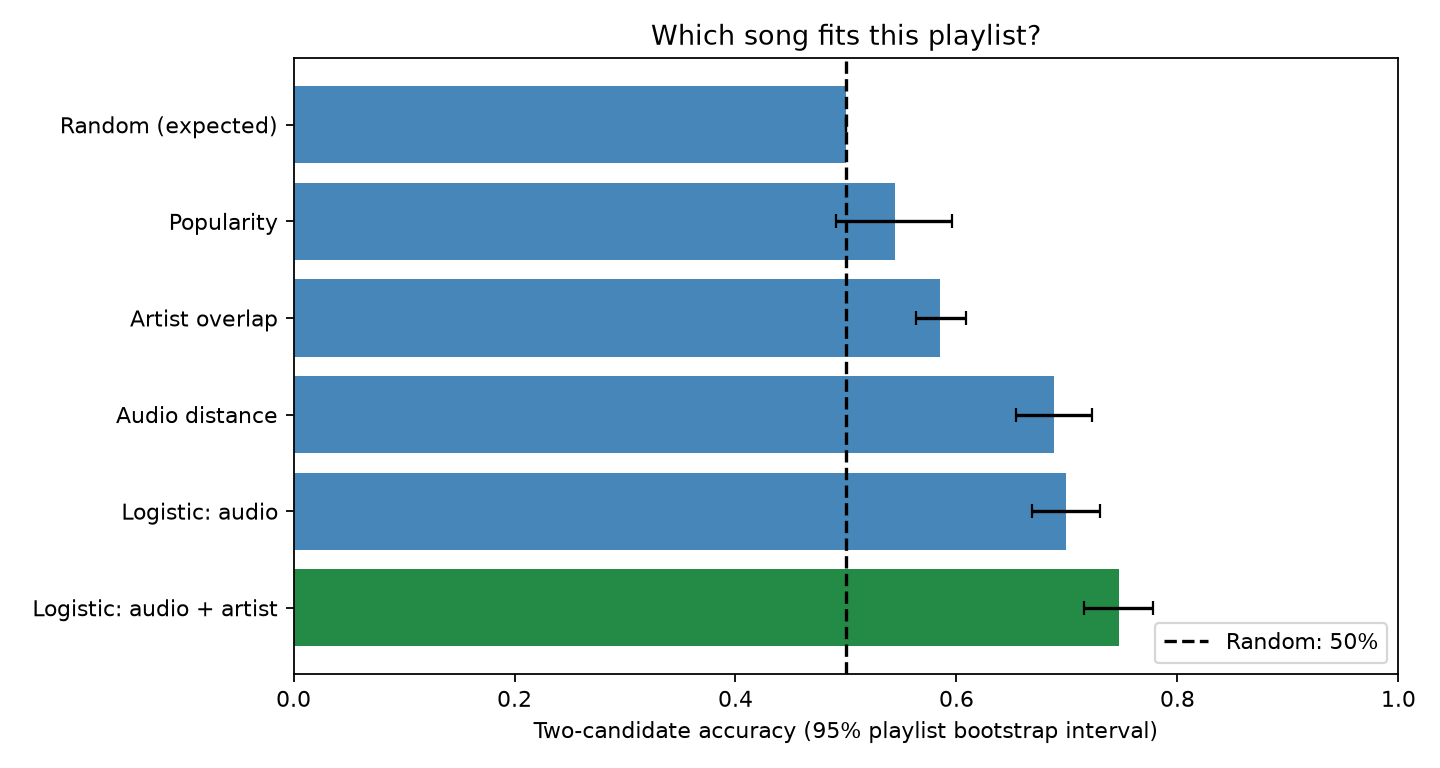

,first,second,difference,ci_low,ci_high,playlists,bootstrap_draws
0,Logistic: audio + artist,Random (expected),0.247,0.215,0.278,100,10000
1,Logistic: audio + artist,Audio distance,0.059,0.034,0.085,100,10000
2,Logistic: audio + artist,Logistic: audio,0.048,0.028,0.070,100,10000


In [7]:
results = run_experiment(data)
summary = results['summary']
display(pd.Series(summary['query_counts'], name='queries').to_frame())
display(results['grid'])
print('Validation-selected primary model:', summary['selection']['primary_model'])
display(results['metrics'].style.format({'accuracy': '{:.1%}', 'ci_low': '{:.1%}',
                                        'ci_high': '{:.1%}', 'tie_fraction': '{:.1%}'}))
display(Image(filename=str(OUT / 'accuracy.png')))
display(pd.DataFrame(summary['comparisons']))

In [8]:
primary = summary['selection']['primary_model']
row = results['metrics'].set_index('model').loc[primary]
baseline = results['metrics'].set_index('model').loc['Audio distance']
comparison = summary['comparisons'][1]
gain = ('The interval supports an improvement over the audio rule.' if comparison['ci_low'] > 0
        else 'The interval does not establish an improvement over the audio rule.'
        if comparison['ci_high'] >= 0 else 'The audio rule performs better in this comparison.')
display(Markdown(f"""**Measured result.** The validation-selected **{primary}** scores
**{row['accuracy']:.1%}** on held-out playlists (95% playlist-bootstrap interval:
{row['ci_low']:.1%}–{row['ci_high']:.1%}). Random guessing scores 50% in expectation.
The simple audio-distance rule scores **{baseline['accuracy']:.1%}**.
The learned model's paired difference from that rule is **{comparison['difference']*100:.1f}
percentage points**, with interval [{comparison['ci_low']*100:.1f}, {comparison['ci_high']*100:.1f}].
{gain}"""))
display(results['subgroups'])
display(results['coefficients'].query('model == @primary').sort_values('coefficient', ascending=False))

**Measured result.** The validation-selected **Logistic: audio + artist** scores
**74.7%** on held-out playlists (95% playlist-bootstrap interval:
71.5%–77.8%). Random guessing scores 50% in expectation.
The simple audio-distance rule scores **68.8%**.
The learned model's paired difference from that rule is **5.9
percentage points**, with interval [3.4, 8.5].
The interval supports an improvement over the audio rule.

,model,member_seen_in_training,accuracy,playlists_with_queries
0,Artist overlap,False,0.590742,91
1,Artist overlap,True,0.580347,94
2,Audio distance,False,0.725611,91
3,Audio distance,True,0.678166,94
4,Logistic: audio,False,0.733032,91
5,Logistic: audio,True,0.714894,94
6,Logistic: audio + artist,False,0.784371,91
7,Logistic: audio + artist,True,0.746243,94
8,Popularity,False,0.074898,91
9,Popularity,True,0.836314,94


,model,feature,coefficient
22,Logistic: audio + artist,artist_fraction,1.719557
21,Logistic: audio + artist,nearest_audio,0.419010
11,Logistic: audio + artist,closeness_danceability,0.366501
18,Logistic: audio + artist,closeness_valence,0.331098
12,Logistic: audio + artist,closeness_energy,0.314401
15,Logistic: audio + artist,closeness_acousticness,0.305970
13,Logistic: audio + artist,closeness_loudness,0.277201
16,Logistic: audio + artist,closeness_instrumentalness,0.255966
14,Logistic: audio + artist,closeness_speechiness,0.253593
20,Logistic: audio + artist,closeness_duration_ms,0.123742


The subgroup table separates queries whose hidden member appeared in a training playlist
from queries whose member did not. Within each subgroup, accuracy first averages within
playlist and then across playlists that have such queries. These are descriptive checks;
they do not select another model. Coefficients use one standard deviation of training
pair differences; correlated features can share or reverse weights.

In [9]:
# Show the first test example, selected by playlist/query ID rather than outcome.
q = results['queries']['test'].sort_values(['pid', 'query']).iloc[0]
seed_items = q[[f'h{i}' for i in range(5)]].to_numpy(dtype=int)
display(data['tracks'].iloc[seed_items][['track_name', 'artist_name']].assign(role='Context'))
example = data['tracks'].iloc[[int(q.candidate_a), int(q.candidate_b)]][['track_name', 'artist_name']].copy()
example.index = ['A', 'B']
example['actual_member'] = [bool(q.label), not bool(q.label)]
display(example)
details = results['details']
prediction = details[(details.model == primary) & (details.pid == q['pid']) &
                     (details['query'] == q['query'])]
score = float(prediction.score_a_minus_b.iloc[0])
print('Model chooses:', 'A' if score > 0 else 'B' if score < 0 else 'Tie: fair coin')

,track_name,artist_name,role
17077,What a Girl Wants,Pia Mia,Context
29851,Search Party - JayKode Remix,Sam Bruno,Context
17470,BLK CLD,XYLØ,Context
25328,Temple - Niko The Kid Remix,Parson James,Context
29441,You Don't Own Me,Grace,Context


,track_name,artist_name,actual_member
A,Nothing But Trouble - Instagram Models,Lil Wayne,True
B,Lower Still,My Epic,False


Model chooses: A


## 5 · Findings, related work, and limits

The measured result and confidence intervals above answer the research question directly.
Compare the learned model to both random guessing and the audio rule before claiming
that a more complex model is useful. Artist overlap may help explain shared performers,
while audio similarity remains available for recordings absent from training playlists.
The paired audio-plus-artist comparison measures the observed incremental benefit of
artist overlap rather than assuming it helps.

**How this relates to existing work.** Spotify's
[2018 playlist-continuation challenge](https://research.atspotify.com/publications/recsys-challenge-2018-automatic-music-playlist-continuation)
studied recommending tracks for existing playlists. Our task shares that motivation but
asks a narrower question: distinguish one observed member from one sampled nonmember.
Its catalogue-retrieval metrics and this notebook's two-candidate accuracy cannot be
compared numerically. The Google Drive presentation linked in Section 2 provides the
project's earlier feature-based grouping and recommendation context; it does not
validate the results of this new experiment.

**Limits that matter when explaining accuracy:**

- A randomly sampled nonmember may be easy to distinguish. Accuracy applies to this
  exact candidate sampler; it does not establish performance against carefully selected
  similar alternatives or over the entire catalogue.
- Absence from a playlist does not imply dislike. The label measures recorded membership,
  not musical quality, listener satisfaction, or whether a new recommendation is welcome.
- Random five-song contexts test playlist compatibility, not the immediate next song.
  Deduplication and context sampling intentionally discard order.
- Playlists are held out, but tracks and artists can overlap across splits. Metadata for
  all candidates is assumed available. No dates support claims about future playlists.
- Different playlist IDs could still share very similar content. The playlist split does
  not guarantee independence of curators or eliminate copied playlists.
- Ten queries per playlist share context and labels. Playlist-bootstrap intervals account
  for this clustering, conditional on the fixed split, sampled queries, and fitted model;
  they do not capture all variation from retraining or another negative sampler.
- The test split has been explored in the earlier next-song task. This is a new task and
  a fixed protocol, not a claim that the underlying data has never been inspected.

**Presentation-ready explanation:** “We show five songs from a playlist and ask our model
to choose which of two other songs was also in it. It compares how similar the songs
sound and whether they share artists. We test it on playlists excluded from training.”

For a stronger follow-up, freeze this model and evaluate a separately defined set of
more similar nonmembers. Do not quietly replace the current test sampler to improve
the headline accuracy.

In [10]:
split_sets = [set(ids) for ids in data['split'].values()]
assert all(split_sets[i].isdisjoint(split_sets[j]) for i in range(3) for j in range(i))
for split, queries in results['queries'].items():
    assert set(queries.pid) <= set(data['split'][split])
    for q in queries.itertuples(index=False):
        context = {getattr(q, f'h{i}') for i in range(5)}
        member = q.candidate_a if q.label else q.candidate_b
        outsider = q.candidate_b if q.label else q.candidate_a
        assert len(context) == 5 and member not in context
        assert context | {member} <= set(data['members'][q.pid])
        assert outsider not in data['members'][q.pid]
print('Verified: disjoint playlist splits, distinct contexts, hidden members, and true nonmembers.')
display(pd.Series(summary['environment'], name='version').to_frame())
print('Dataset SHA-256:', summary['data']['dataset_sha256'])

Verified: disjoint playlist splits, distinct contexts, hidden members, and true nonmembers.


,version
python,3.14.4
numpy,2.5.5
pandas,3.1.1
sklearn,1.9.1


Dataset SHA-256: 11533e4997668e7791c093bbcc63fb20ed820e8c4bbd80b7026fedaf1fb8d946
